# Práctica 3: Regresión polinomial
### Predecir el rendimiento de combustible de un automóvil (INF672 · Machine Learning · Unidad 3)

## Paso 01: Preparar el entorno de trabajo

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_squared_error, r2_score


Se importan pandas para manejar la tabla de datos, numpy para generar valores numéricos como la malla de potencias y matplotlib.pyplot para graficar. De scikit-learn se usa cada herramienta con un propósito distinto, resumido en la siguiente tabla.

| Función | Para qué se usará |
|---|---|
| train_test_split | Separar los autos en un conjunto de entrenamiento y uno de prueba que quede reservado para la evaluación final |
| cross_val_score | Calcular el error de un modelo mediante validación cruzada, sin tocar el conjunto de prueba |
| KFold | Definir cómo se divide el conjunto de entrenamiento en pliegues para la validación cruzada |
| PolynomialFeatures | Generar las columnas con las potencias de la potencia del motor (x, x², ...) |
| StandardScaler | Escalar la variable de entrada a media 0 y desviación estándar 1 antes de elevarla a potencias |
| LinearRegression | Ajustar la regresión lineal, tanto el modelo base como el ajuste sobre las columnas polinomiales |
| make_pipeline | Encadenar escalado, generación de potencias y regresión en un solo objeto que se aplica siempre en el mismo orden |
| mean_squared_error | Calcular el error cuadrático medio, del cual se obtiene el RMSE |
| r2_score | Calcular la proporción de la variación del rendimiento que explica el modelo |

## Paso 02: Cargar y explorar los datos

In [2]:
df = pd.read_csv('mpg.csv')
print(df.shape)
df.head()

(398, 9)


,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,name
0,18.0,8,307.0,130.0,3504,12.0,70,usa,chevrolet chevelle malibu
1,15.0,8,350.0,165.0,3693,11.5,70,usa,buick skylark 320
2,18.0,8,318.0,150.0,3436,11.0,70,usa,plymouth satellite
3,16.0,8,304.0,150.0,3433,12.0,70,usa,amc rebel sst
4,17.0,8,302.0,140.0,3449,10.5,70,usa,ford torino


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 398 entries, 0 to 397
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   mpg           398 non-null    float64
 1   cylinders     398 non-null    int64  
 2   displacement  398 non-null    float64
 3   horsepower    392 non-null    float64
 4   weight        398 non-null    int64  
 5   acceleration  398 non-null    float64
 6   model_year    398 non-null    int64  
 7   origin        398 non-null    str    
 8   name          398 non-null    str    
dtypes: float64(4), int64(3), str(2)
memory usage: 28.1 KB


In [4]:
df.isna().sum()

mpg             0
cylinders       0
displacement    0
horsepower      6
weight          0
acceleration    0
model_year      0
origin          0
name            0
dtype: int64

In [5]:
df.describe()

,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year
count,398.000000,398.000000,398.000000,392.000000,398.000000,398.000000,398.000000
mean,23.514573,5.454774,193.425879,104.469388,2970.424623,15.568090,76.010050
std,7.815984,1.701004,104.269838,38.491160,846.841774,2.757689,3.697627
min,9.000000,3.000000,68.000000,46.000000,1613.000000,8.000000,70.000000
25%,17.500000,4.000000,104.250000,75.000000,2223.750000,13.825000,73.000000
50%,23.000000,4.000000,148.500000,93.500000,2803.500000,15.500000,76.000000
75%,29.000000,8.000000,262.000000,126.000000,3608.000000,17.175000,79.000000
max,46.600000,8.000000,455.000000,230.000000,5140.000000,24.800000,82.000000


El dataset tiene 398 automóviles (una fila por auto) y 9 columnas. Sí hay valores faltantes: únicamente la columna horsepower tiene 6 vacíos, y las demás columnas están completas. El rendimiento mpg varía entre 9.0 y 46.6 millas por galón, y la potencia horsepower varía entre 46 y 230 hp (sin contar los 6 autos sin dato).

## Paso 03: Elegir el predictor

In [6]:
correlaciones = df.select_dtypes('number').corr()['mpg'].sort_values()
correlaciones

weight         -0.831741
displacement   -0.804203
horsepower     -0.778427
cylinders      -0.775396
acceleration    0.420289
model_year      0.579267
mpg             1.000000
Name: mpg, dtype: float64

Las variables con la relación más fuerte con mpg son weight (-0.83), displacement (-0.80), horsepower (-0.78) y cylinders (-0.78). Las más débiles son acceleration (0.42) y model_year (0.58), esta última con signo positivo.

El signo negativo significa que, a mayor peso, cilindrada, potencia o número de cilindros, menor es el rendimiento: un auto más pesado y con un motor más grande y potente consume más combustible y por tanto recorre menos millas por galón. El signo positivo de model_year indica que los modelos más recientes tienden a rendir más.

La correlación de Pearson solo mide qué tan bien se ajustan los datos a una recta. Una variable cuya relación con mpg es claramente curva puede mostrar una correlación moderada, porque una recta describe solo una parte de esa relación, aunque exista una asociación fuerte y muy regular. Por eso horsepower es un buen candidato para la regresión polinomial: su correlación no es la más alta, pero si la relación es curva, un polinomio puede capturar la parte que la recta pierde.

## Paso 04: Limpiar los datos

In [7]:
datos = df[['horsepower', 'mpg']].copy()
print('Filas antes de la limpieza:', len(datos))

datos = datos.dropna()
print('Filas después de la limpieza:', len(datos))
print(f'Porcentaje eliminado: {(len(df) - len(datos)) / len(df) * 100:.2f} %')

Filas antes de la limpieza: 398
Filas después de la limpieza: 392
Porcentaje eliminado: 1.51 %


Antes de la limpieza había 398 filas y después quedaron 392, es decir, se eliminaron 6 filas, el 1.51 % de los datos. En este caso es razonable eliminarlas porque son muy pocas, y el modelo solo necesita horsepower y mpg: un auto sin horsepower no aporta nada al entrenamiento. Además, rellenar el dato con una media o una mediana inventaría una potencia que no es la del auto y podría distorsionar justamente la relación que se quiere estudiar.

Preferiría imputar los valores cuando la proporción de datos faltantes fuera grande, de modo que eliminar filas hiciera perder una parte importante de la información, o cuando los faltantes se concentraran en un grupo específico de casos (por ejemplo, un tipo de auto), porque eliminarlos sesgaría la muestra.

## Paso 05: Visualizar la relación

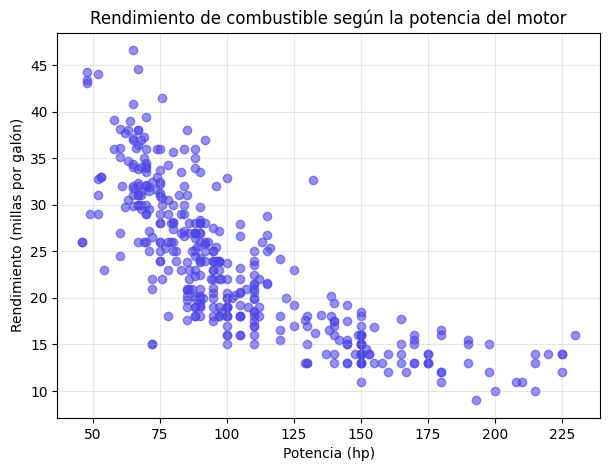

In [8]:
plt.figure(figsize=(7, 5))
plt.scatter(datos['horsepower'], datos['mpg'], alpha=0.6, color='#4F46E5')
plt.xlabel('Potencia (hp)')
plt.ylabel('Rendimiento (millas por galón)')
plt.title('Rendimiento de combustible según la potencia del motor')
plt.grid(alpha=0.3)
plt.show()

La relación es decreciente y curva. El rendimiento no disminuye al mismo ritmo en todo el rango: entre los autos de menos de 70 hp, el rendimiento promedio ronda las 34 mpg, mientras que entre 70 y 100 hp baja a unas 25 mpg, una caída muy brusca de unas 9 mpg en un tramo corto de potencia. En cambio, de los autos de 130 a 160 hp (unas 15.5 mpg) a los de más de 160 hp (unas 13.4 mpg) la caída es de apenas 2 mpg, y la nube de puntos se aplana cerca de las 10 a 15 mpg.

Por eso una recta probablemente no represente bien estos datos: tendría que descender a un ritmo constante, y quedaría por debajo de los puntos en el extremo izquierdo (potencias bajas), por encima de ellos en la zona central y de nuevo por debajo en el extremo derecho. La forma de la nube es la de una curva convexa (una "L" suavizada), no la de una recta.

## Paso 06: Dividir en entrenamiento y prueba

In [9]:
X = datos[['horsepower']]
y = datos['mpg']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)

print('Entrenamiento:', X_train.shape[0], 'filas')
print('Prueba:', X_test.shape[0], 'filas')
print('X_train.shape:', X_train.shape)
print('y_train.shape:', y_train.shape)

Entrenamiento: 313 filas
Prueba: 79 filas
X_train.shape: (313, 1)
y_train.shape: (313,)


Quedaron 313 autos en el conjunto de entrenamiento y 79 en el de prueba.

X se define con doble corchete porque `datos[['horsepower']]` devuelve un DataFrame (una tabla de 2 dimensiones: filas y columnas), mientras que y se define con un solo corchete porque `datos['mpg']` devuelve una Serie (un vector de 1 dimensión). La forma de X_train es (313, 1), es decir, 313 filas y 1 columna, y la de y_train es (313,), un vector de 313 valores. scikit-learn exige esta diferencia porque espera que las características (X) sean siempre una matriz 2D de forma (muestras, características), aunque haya una sola característica, mientras que el objetivo (y) es un vector con un valor por muestra.

## Paso 07: Entrenar el modelo base: regresión lineal

In [10]:
modelo_lineal = LinearRegression()
modelo_lineal.fit(X_train, y_train)

y_pred_lin = modelo_lineal.predict(X_test)

rmse_lin = np.sqrt(mean_squared_error(y_test, y_pred_lin))
r2_lin = r2_score(y_test, y_pred_lin)

print(f'RMSE lineal = {rmse_lin:.4f} mpg')
print(f'R² lineal   = {r2_lin:.4f}')

RMSE lineal = 4.7067 mpg


R² lineal   = 0.5660


El modelo lineal obtuvo un RMSE de 4.707 mpg y un R² de 0.566. El RMSE indica que, en promedio, las predicciones del modelo se desvían unas 4.7 millas por galón del rendimiento real, con mayor peso para los errores grandes. Para un rango de rendimientos que va de 9 a 46.6 mpg, y con un auto típico de alrededor de 23 mpg, es un error considerable. El R² indica que el modelo lineal explica aproximadamente el 57 % de la variación del rendimiento en el conjunto de prueba; el 43 % restante queda sin explicar.

## Paso 08: Entrenar un modelo polinomial de grado 2

In [11]:
modelo_poly2 = make_pipeline(StandardScaler(), PolynomialFeatures(degree=2), LinearRegression())
modelo_poly2.fit(X_train, y_train)

y_pred_poly2 = modelo_poly2.predict(X_test)

rmse_poly2 = np.sqrt(mean_squared_error(y_test, y_pred_poly2))
r2_poly2 = r2_score(y_test, y_pred_poly2)

print(f'Lineal       -> RMSE = {rmse_lin:.4f}   R² = {r2_lin:.4f}')
print(f'Polinomial 2 -> RMSE = {rmse_poly2:.4f}   R² = {r2_poly2:.4f}')

Lineal       -> RMSE = 4.7067   R² = 0.5660
Polinomial 2 -> RMSE = 4.2915   R² = 0.6392


In [12]:
escalador = modelo_poly2.named_steps['standardscaler']
polinomio = modelo_poly2.named_steps['polynomialfeatures']

tres_autos = X_train.iloc[:3]
columnas_generadas = polinomio.transform(escalador.transform(tres_autos))

tabla_columnas = pd.DataFrame(
    columnas_generadas,
    columns=polinomio.get_feature_names_out(['horsepower']),
    index=tres_autos.index)
tabla_columnas

,1,horsepower,horsepower^2
260,1.0,0.141429,0.020002
184,1.0,-0.329499,0.108569
174,1.0,-0.198685,0.039476


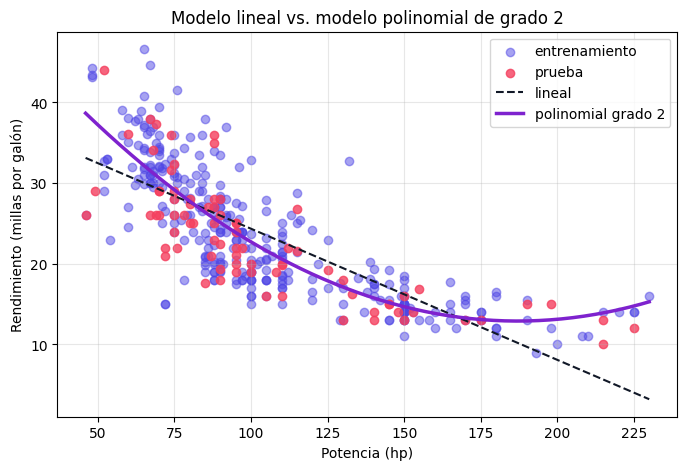

In [13]:
xs = np.linspace(X['horsepower'].min(), X['horsepower'].max(), 200)
xs_df = pd.DataFrame({'horsepower': xs})

plt.figure(figsize=(8, 5))
plt.scatter(X_train, y_train, alpha=0.5, color='#4F46E5', label='entrenamiento')
plt.scatter(X_test, y_test, alpha=0.8, color='#F43F5E', label='prueba')
plt.plot(xs, modelo_lineal.predict(xs_df), color='#111827', linestyle='--', label='lineal')
plt.plot(xs, modelo_poly2.predict(xs_df), color='#7E22CE', linewidth=2.5, label='polinomial grado 2')
plt.xlabel('Potencia (hp)')
plt.ylabel('Rendimiento (millas por galón)')
plt.title('Modelo lineal vs. modelo polinomial de grado 2')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

Las métricas de prueba son: modelo lineal con RMSE 4.707 y R² 0.566; modelo polinomial de grado 2 con RMSE 4.291 y R² 0.639. El modelo polinomial reduce el error y explica más variación.

PolynomialFeatures genera tres columnas a partir de horsepower: la columna `1`, que es una constante igual a 1 en todas las filas y funciona como término independiente (el sesgo, β₀); la columna `horsepower`, que es la potencia ya escalada (el término lineal, β₁·x); y la columna `horsepower^2`, que es el cuadrado de la potencia escalada (el término cuadrático, β₂·x²). Por ejemplo, para el primer auto la potencia escalada vale 0.1414 y su cuadrado 0.0200, valores que se ven en la tabla.

Se escala la variable antes de elevarla al cuadrado porque la potencia llega hasta 230, y su cuadrado hasta más de 52.000: las dos columnas quedarían en escalas muy distintas y fuertemente correlacionadas entre sí. Al escalar primero (media 0 y desviación 1), x y x² quedan en magnitudes comparables, lo que hace el ajuste numéricamente más estable y evita que potencias altas produzcan valores enormes.

Según los residuos del entrenamiento, la recta se equivoca más en los extremos: en los autos de menos de 70 hp el modelo lineal subestima el rendimiento real en unas 3.7 mpg en promedio, y en los de más de 160 hp lo subestima en unas 3.3 mpg, mientras que en la zona central (100 a 130 hp) lo sobreestima en unas 2.1 mpg. La curva corrige esos errores porque se dobla hacia arriba en los extremos y baja en el centro: con ella los errores promedio por tramo se reducen a 1.2, 0.0 y 0.1 mpg en esas mismas zonas.

## Paso 09: Elegir el grado con validación cruzada

In [14]:
kfold = KFold(n_splits=10, shuffle=True, random_state=42)

resultados = []
for grado in range(1, 11):
    pipeline = make_pipeline(StandardScaler(), PolynomialFeatures(degree=grado), LinearRegression())
    puntajes = cross_val_score(pipeline, X_train, y_train, cv=kfold,
                               scoring='neg_root_mean_squared_error')
    resultados.append({'grado': grado, 'rmse_cv': -puntajes.mean(), 'desv_est': puntajes.std()})

tabla_cv = pd.DataFrame(resultados)
tabla_cv

,grado,rmse_cv,desv_est
0,1,4.958557,0.503094
1,2,4.385783,0.658141
2,3,4.390351,0.670325
3,4,4.404014,0.669686
4,5,4.354005,0.687579
5,6,4.347532,0.720872
6,7,4.354589,0.727604
7,8,4.404464,0.708039
8,9,4.422114,0.727959
9,10,4.499858,0.766640


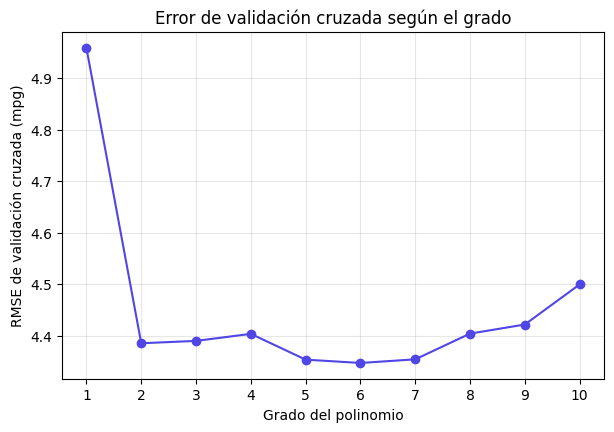

Grado con menor RMSE de validación cruzada: 6


In [15]:
plt.figure(figsize=(7, 4.5))
plt.plot(tabla_cv['grado'], tabla_cv['rmse_cv'], marker='o', color='#4F46E5')
plt.xticks(range(1, 11))
plt.xlabel('Grado del polinomio')
plt.ylabel('RMSE de validación cruzada (mpg)')
plt.title('Error de validación cruzada según el grado')
plt.grid(alpha=0.3)
plt.show()

mejor_grado = int(tabla_cv.loc[tabla_cv['rmse_cv'].idxmin(), 'grado'])
print('Grado con menor RMSE de validación cruzada:', mejor_grado)

El error cae con claridad al pasar del grado 1 (RMSE 4.959) al grado 2 (4.386). A partir de ahí se mantiene prácticamente plano, entre 4.35 y 4.42, hasta el grado 8, y vuelve a subir en los grados 9 y 10 (4.42 y 4.50), señal del comienzo del sobreajuste. El grado con el menor error es el 6 (RMSE 4.348), pero su ventaja sobre el grado 2 es de apenas unas 0.04 mpg, una diferencia muy inferior a la variabilidad entre pliegues (la desviación estándar del error por pliegue ronda las 0.7 mpg).

Por eso el grado con menor error no es necesariamente el mejor. Entre modelos de rendimiento prácticamente igual, el principio de parsimonia indica elegir el más simple: el grado 2 logra casi todo el beneficio de la curva con solo tres parámetros, es más fácil de interpretar y tiene menor riesgo de sobreajustarse, mientras que el grado 6 agrega complejidad sin una mejora que se pueda distinguir del ruido. **El grado elegido para el modelo final es 2.**

No se debe usar el conjunto de prueba para elegir el grado porque entonces dejaría de ser una evaluación imparcial: si se prueban varios grados contra el conjunto de prueba y se queda con el que mejor le va, ese conjunto pasa a participar en la decisión del modelo, y su error ya no estima cómo se comportaría con autos realmente nuevos (queda optimista). La validación cruzada sobre los datos de entrenamiento permite comparar grados sin tocar el conjunto de prueba, que se reserva para una única evaluación final.

## Paso 10: Evaluar el modelo final

In [16]:
grado_final = 2
modelo_final = make_pipeline(StandardScaler(), PolynomialFeatures(degree=grado_final), LinearRegression())
modelo_final.fit(X_train, y_train)

y_pred_final = modelo_final.predict(X_test)
rmse_final = np.sqrt(mean_squared_error(y_test, y_pred_final))
r2_final = r2_score(y_test, y_pred_final)

comparacion = pd.DataFrame({
    'RMSE (mpg)': [rmse_lin, rmse_final],
    'R²': [r2_lin, r2_final]},
    index=['Lineal', f'Polinomial grado {grado_final}'])
comparacion

,RMSE (mpg),R²
Lineal,4.706723,0.565968
Polinomial grado 2,4.291499,0.639170


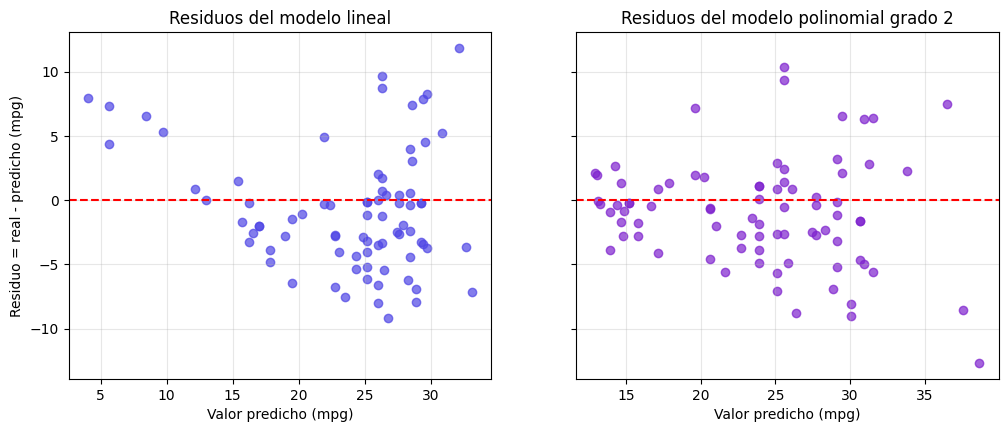

In [17]:
residuos_lin = y_test - y_pred_lin
residuos_final = y_test - y_pred_final

fig, ejes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)

ejes[0].scatter(y_pred_lin, residuos_lin, alpha=0.7, color='#4F46E5')
ejes[0].axhline(0, color='red', linestyle='--')
ejes[0].set_title('Residuos del modelo lineal')
ejes[0].set_xlabel('Valor predicho (mpg)')
ejes[0].set_ylabel('Residuo = real - predicho (mpg)')
ejes[0].grid(alpha=0.3)

ejes[1].scatter(y_pred_final, residuos_final, alpha=0.7, color='#7E22CE')
ejes[1].axhline(0, color='red', linestyle='--')
ejes[1].set_title(f'Residuos del modelo polinomial grado {grado_final}')
ejes[1].set_xlabel('Valor predicho (mpg)')
ejes[1].grid(alpha=0.3)

plt.show()

In [18]:
modelo_original = make_pipeline(PolynomialFeatures(degree=grado_final, include_bias=False), LinearRegression())
modelo_original.fit(X_train, y_train)

regresor = modelo_original.named_steps['linearregression']
b0 = regresor.intercept_
b1, b2 = regresor.coef_

print(f'mpg = {b0:.4f} + ({b1:.5f}) · hp + ({b2:.7f}) · hp²')

mpg = 58.2129 + (-0.48446) · hp + (0.0012949) · hp²


La tabla comparativa muestra que el modelo final (grado 2) logró un RMSE de 4.291 frente a 4.707 del modelo lineal, es decir, una reducción de unas 0.42 mpg (cerca del 9 %), y un R² de 0.639 frente a 0.566, unos 7 puntos porcentuales más de variación explicada. La mejora es real pero moderada: buena parte de la variación del rendimiento sigue sin explicarse con la potencia sola, algo esperable porque otras variables como el peso también influyen.

En los residuos del modelo lineal se observa un patrón en forma de arco en lugar de una nube al azar: los residuos tienden a ser negativos en la zona central (el modelo sobreestima el rendimiento de los autos con rendimiento intermedio) y positivos en los extremos, sobre todo en los autos de potencia alta, donde el modelo lo subestima. Ese patrón sistemático significa que el modelo lineal no capturó la forma de la relación: el error no es azar, sino curvatura sin modelar. En el modelo final ese patrón se atenúa de forma clara: los residuos se reparten más cerca de cero en las zonas central y alta, aunque el conjunto de prueba tiene solo 79 autos y, por eso, el patrón se aprecia con menos nitidez que en los datos de entrenamiento. Queda cierta dispersión por factores que la potencia sola no explica.

La ecuación del modelo final, en unidades originales, es: mpg = 58.2129 − 0.48446·hp + 0.0012949·hp².

El signo negativo del coeficiente lineal (−0.48446) describe la tendencia principal: al aumentar la potencia, el rendimiento baja, y lo hace con rapidez. El signo positivo del coeficiente cuadrático (+0.0012949) indica que la curva es convexa, abre hacia arriba: el ritmo de descenso se va suavizando a medida que crece la potencia, lo que coincide con la forma de "L" suavizada de la nube de puntos. El intercepto (58.21) es el rendimiento que el modelo asignaría a una potencia de 0 hp, que no existe en los datos y no tiene interpretación práctica.

## Paso 11: Predecir y reconocer los límites del modelo

In [19]:
potencias = pd.DataFrame({'horsepower': [60, 100, 150, 200]})
potencias['mpg_predicho'] = modelo_final.predict(potencias[['horsepower']]).round(2)
potencias

,horsepower,mpg_predicho
0,60,33.81
1,100,22.72
2,150,14.68
3,200,13.12


In [20]:
vertice = -b1 / (2 * b2)
mpg_vertice = b0 + b1 * vertice + b2 * vertice ** 2

print(f'Vértice de la parábola: {vertice:.2f} hp')
print(f'mpg en el vértice: {mpg_vertice:.2f}')
print(f'Rango de potencias en los datos: {X["horsepower"].min():.0f} a {X["horsepower"].max():.0f} hp')
print(f'Autos con más de {vertice:.0f} hp:', (X['horsepower'] > vertice).sum(), 'de', len(X))

Vértice de la parábola: 187.06 hp
mpg en el vértice: 12.90
Rango de potencias en los datos: 46 a 230 hp
Autos con más de 187 hp: 17 de 392


In [21]:
fuera_del_rango = pd.DataFrame({'horsepower': [250, 300, 400]})
fuera_del_rango['mpg_predicho'] = modelo_final.predict(fuera_del_rango[['horsepower']]).round(2)
fuera_del_rango

,horsepower,mpg_predicho
0,250,18.03
1,300,29.42
2,400,71.61


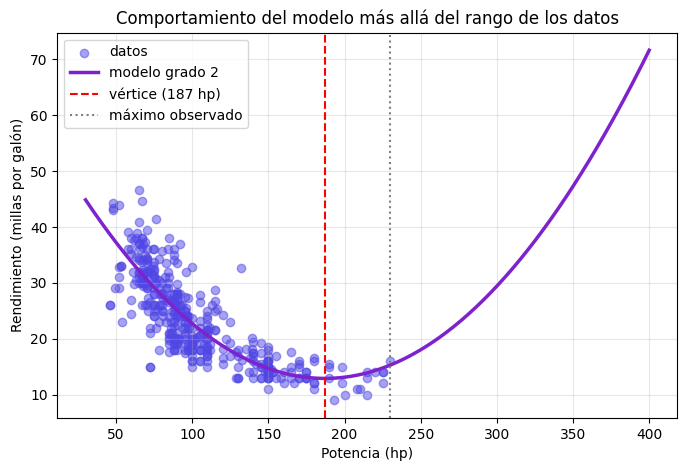

In [22]:
xs_amplio = pd.DataFrame({'horsepower': np.linspace(30, 400, 300)})

plt.figure(figsize=(8, 5))
plt.scatter(X, y, alpha=0.5, color='#4F46E5', label='datos')
plt.plot(xs_amplio['horsepower'], modelo_final.predict(xs_amplio), color='#7E22CE', linewidth=2.5, label='modelo grado 2')
plt.axvline(vertice, color='red', linestyle='--', label=f'vértice ({vertice:.0f} hp)')
plt.axvline(X['horsepower'].max(), color='gray', linestyle=':', label='máximo observado')
plt.xlabel('Potencia (hp)')
plt.ylabel('Rendimiento (millas por galón)')
plt.title('Comportamiento del modelo más allá del rango de los datos')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

Las predicciones del modelo final son: 60 hp → 33.81 mpg; 100 hp → 22.72 mpg; 150 hp → 14.68 mpg; 200 hp → 13.12 mpg. Hasta 150 hp tienen sentido físico: el rendimiento baja de forma consistente al aumentar la potencia. En 200 hp, en cambio, el modelo ya empieza a predecir un valor mayor que el mínimo de la curva, lo cual es una señal de alerta.

El vértice de la parábola está en xᵥ = −β₁ / (2·β₂) = 0.48446 / (2 · 0.0012949) ≈ 187.06 hp, donde el modelo predice su valor mínimo, unos 12.90 mpg. Ese punto sí está dentro del rango de los datos (46 a 230 hp), pero cerca de su extremo superior: solo 17 de los 392 autos tienen más de 187 hp, por lo que el modelo tiene muy pocos datos que lo respalden en esa zona.

Más allá del vértice la parábola cambia de tendencia y empieza a subir: el modelo predice que el rendimiento aumenta con la potencia (18.03 mpg a 250 hp, 29.42 mpg a 300 hp y 71.61 mpg a 400 hp). Eso no es realista: un motor más potente no consume menos combustible, y un rendimiento de 71 mpg para un motor de 400 hp es físicamente absurdo. La curva sube simplemente porque un polinomio de grado 2 debe, matemáticamente, abrirse hacia arriba tras su vértice, aunque los datos reales sigan aplanándose cerca de un mínimo.

La extrapolación consiste en usar el modelo para predecir fuera del rango de valores con el que fue entrenado. Es riesgosa con modelos polinomiales porque la forma del polinomio fuera del rango observado no está respaldada por ningún dato: los términos de grado alto crecen muy rápido y dominan el resultado, de modo que las predicciones pueden divergir o cambiar de tendencia de forma arbitraria. Por eso las predicciones de este modelo solo son confiables dentro del rango de los datos y, con más prudencia, hasta unos 150 a 160 hp, antes de que el vértice y la escasez de datos empiecen a distorsionarlas.

## Paso 12: Conclusiones

Se partió de la pregunta de cuántas millas por galón recorre un auto según su potencia. Tras revisar la calidad de los datos (6 autos sin dato de horsepower, eliminados por ser el 1.5 % del total), se eligió horsepower como predictor y se comprobó con un diagrama de dispersión que su relación con mpg es decreciente y curva. Se entrenó un modelo lineal base (RMSE 4.707 mpg, R² 0.566) y un modelo polinomial de grado 2 (RMSE 4.291 mpg, R² 0.639), y se eligió el grado mediante validación cruzada de 10 pliegues sobre el conjunto de entrenamiento, sin usar el de prueba. El grado 6 tuvo el menor error, pero la diferencia respecto al grado 2 era mínima y quedaba dentro del ruido, así que, por parsimonia, se eligió el grado 2. El modelo final redujo el error en unas 0.42 mpg y eliminó en buena medida el patrón de curvatura que quedaba en los residuos del modelo lineal.

La relación entre potencia y rendimiento tiene forma de curva convexa: el rendimiento cae rápidamente al pasar de potencias bajas a medias y se va aplanando en las potencias altas. Recomiendo el grado 2, porque captura esa curvatura con solo tres parámetros, es interpretable y no se sobreajusta, mientras que los grados superiores no mejoran el error de forma apreciable.

Las limitaciones del modelo son varias. Usa una sola variable, así que deja sin explicar cerca del 36 % de la variación del rendimiento (otras variables como el peso también influyen). Fuera del rango de los datos, y también hacia el extremo superior (por encima de unos 160 a 190 hp, donde hay muy pocos autos), predice valores sin sentido físico, porque la parábola cambia de tendencia en 187 hp. Solo confiaría en sus predicciones dentro de aproximadamente 46 a 160 hp, el tramo donde los datos son abundantes y la curva se comporta de forma coherente.

La regresión polinomial sigue siendo una regresión lineal porque el modelo es lineal en sus coeficientes: ŷ = β₀ + β₁·x + β₂·x². Lo que se hace es transformar la variable de entrada creando columnas nuevas (x y x²) y, sobre esas columnas, ajustar una regresión lineal común, que calcula los coeficientes por mínimos cuadrados. La curva aparece en la relación entre x e y, pero no en la forma en que los parámetros entran en el modelo: cada uno solo multiplica una columna y se suman los resultados.